# fttxplan quick start

This notebook designs a complete FTTx network for a real neighbourhood (1,591 buildings from OpenStreetMap, bundled with the package), then looks at the bill of materials, the optical budget and a comparison of split architectures.

In [1]:
import fttxplan
import matplotlib.pyplot as plt

roads, buildings, olt = fttxplan.load_demo()
print(len(roads), 'road segments,', len(buildings), 'buildings')

187 road segments, 1591 buildings


## Plan the network

One call does everything: road graph, attachment, splitter and cabinet placement, routing, cable sizing and the loss budget.

In [2]:
design = fttxplan.plan(roads, olt, buildings, split_levels='1:4x1:8')
print(design.report())

FTTx design  (1:4 x 1:8 (1:32) split, 1591 premises)
  PON ports         50  (4 OLT card(s))
  Splitters         50 x 1:4 FDH, 199 x 1:8 FAT  in 7 cabinet(s)
  Feeder cable      5.00 km
  Distribution      24.40 km
  Drop cable        166.55 km
  Trench            30.01 km  (sharing saves 91% vs separate routes)
  Longest path      5857 m  (reach limit 12250 m)
  Worst margin      5.65 dB  (0 premises below the 3 dB margin)
  Long drops        59  (> 150 m from a road)
  Computed in       1.9 s


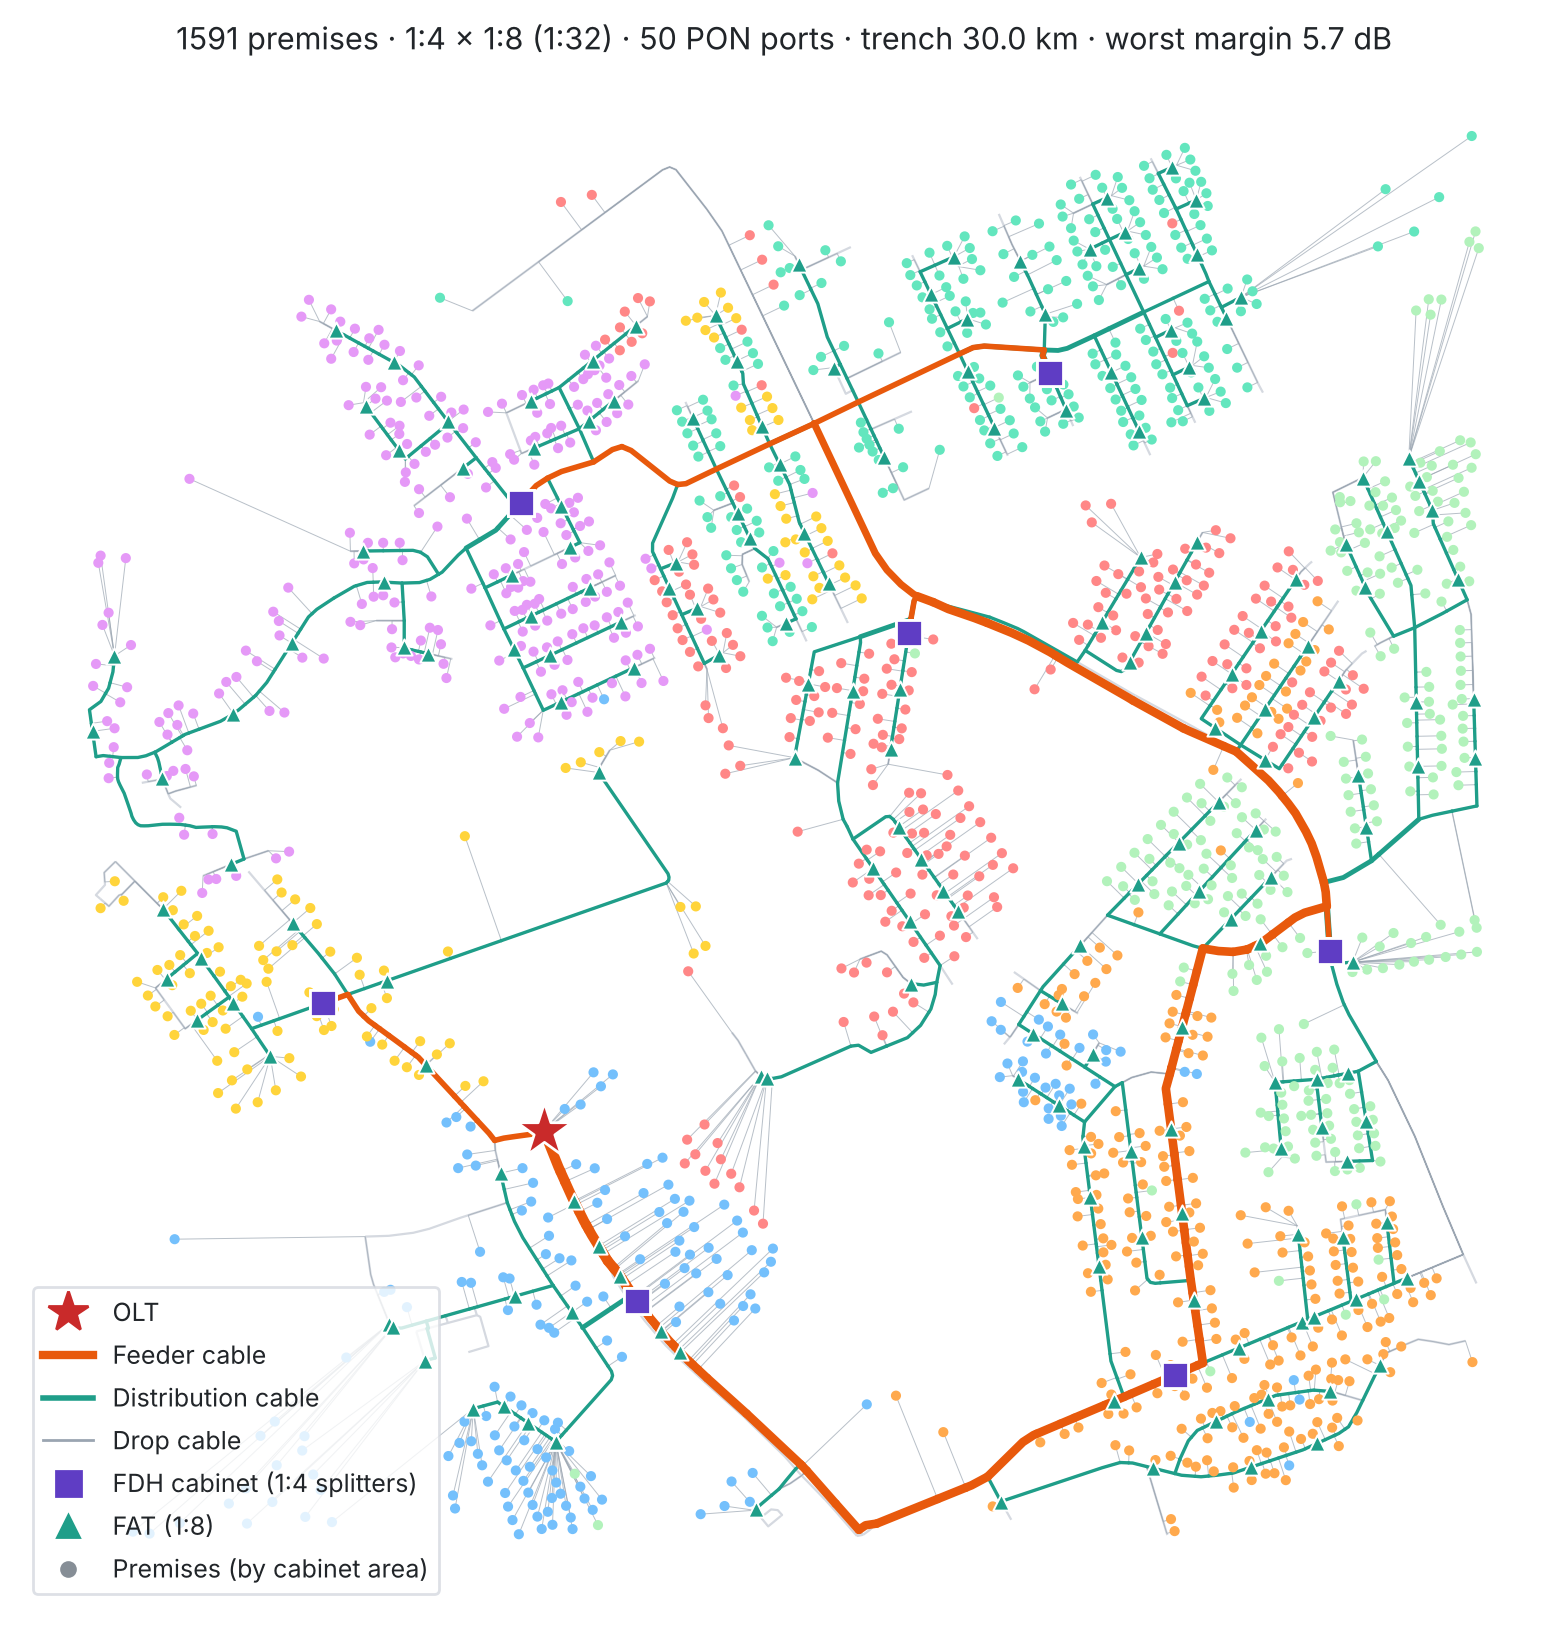

In [3]:
design.plot(figsize=(10, 10));

## Bill of materials

Pass your own unit prices to get a cost estimate. The prices below are placeholders for illustration only; replace them with your supplier's rates.

In [4]:
prices = {
    'Distribution cable 12F': 0.6, 'Feeder cable 48F': 1.4, 'Drop cable 1F': 0.15,
    'PLC splitter 1:4 (level 1)': 6, 'PLC splitter 1:8 (level 2)': 9,
    'Fiber distribution hub (FDH) cabinet': 900, 'Fiber access terminal (FAT)': 35,
    'Trench / duct route': 8, 'ONT / ONU': 22,
}
bom = design.bom(prices)
bom

,category,item,quantity,unit,unit_cost,cost
0,Cable,Feeder cable 12F,1688,m,NaN,NaN
1,Cable,Feeder cable 24F,353,m,NaN,NaN
2,Cable,Feeder cable 48F,3122,m,1.40,4370.8
3,Cable,Feeder cable 96F,338,m,NaN,NaN
4,Cable,Distribution cable 12F,24757,m,0.60,14854.2
5,Cable,Distribution cable 24F,1836,m,NaN,NaN
6,Cable,Distribution cable 48F,250,m,NaN,NaN
7,Cable,Drop cable 1F,183200,m,0.15,27480.0
8,Passive,PLC splitter 1:4 (level 1),50,pcs,6.00,300.0
9,Passive,PLC splitter 1:8 (level 2),199,pcs,9.00,1791.0


In [5]:
print(f"Estimated cost of the priced items: {bom.cost.sum():,.0f}")

Estimated cost of the priced items: 337,006


## Optical budget

Every premise gets its own loss calculation. The worst ones come first.

In [6]:
design.loss_budget().head(10)

,premise_id,fat_id,path_m,loss_db,margin_db,budget_ok
0,P0393,FAT-148,5856.9,22.35,5.65,True
1,P0367,FAT-034,5577.9,22.25,5.75,True
2,P0827,FAT-160,5468.1,22.21,5.79,True
3,P1472,FAT-131,5409.2,22.19,5.81,True
4,P0643,FAT-125,5288.9,22.15,5.85,True
5,P0004,FAT-027,5279.3,22.15,5.85,True
6,P1565,FAT-027,5232.7,22.13,5.87,True
7,P0149,FAT-027,5191.0,22.12,5.88,True
8,P0195,FAT-027,5194.8,22.12,5.88,True
9,P0761,FAT-027,5210.4,22.12,5.88,True


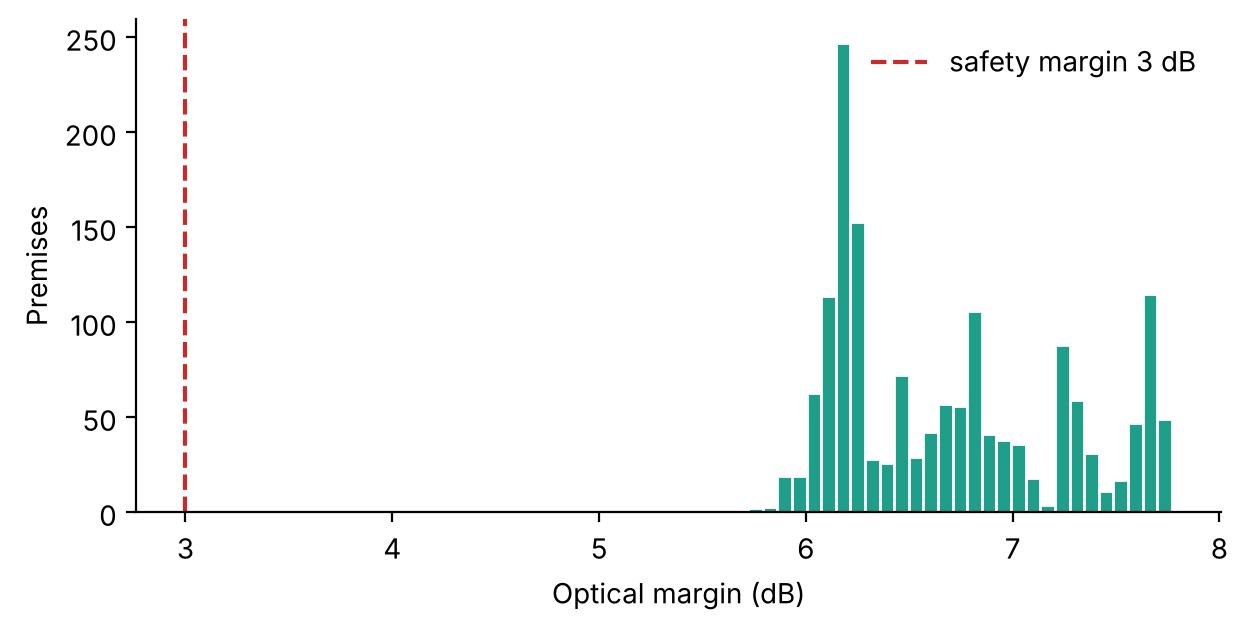

In [7]:
from fttxplan.plot import plot_budget
plot_budget(design);

## Compare architectures

In [8]:
import pandas as pd
import warnings
rows = []
for arch in ['1:32', '1:4x1:8', '1:8x1:8', '1:2x1:16']:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        s = fttxplan.plan(roads, olt, buildings, split_levels=arch).summary()
    rows.append({'architecture': s['architecture'], 'PON ports': s['pon_ports'], 'feeder km': s['feeder_km'],
                 'distribution km': s['distribution_km'], 'drop km': s['drop_km'], 'trench km': s['trench_km'],
                 'worst margin dB': round(s['worst_margin_db'], 2), 'below margin': s['budget_failures']})
pd.DataFrame(rows)

,architecture,PON ports,feeder km,distribution km,drop km,trench km,worst margin dB,below margin
0,1:32,50,14.731,0.000,324.599,30.244,6.60,0
1,1:4 x 1:8 (1:32),50,5.000,24.402,166.546,30.006,5.65,0
2,1:8 x 1:8 (1:64),27,4.279,23.791,166.546,29.905,2.07,543
3,1:2 x 1:16 (1:32),50,5.443,20.205,276.848,30.238,5.84,0


## Export

Open `design.gpkg` in QGIS or ArcGIS Pro, or `design.kml` in Google Earth.

In [9]:
design.to_gpkg('design.gpkg')
design.to_kml('design.kml')
design.layers()['splitters'].head()

,splitter_id,cabinet_id,role,level,ratio,parent_id,ports_used,utilisation,link_m,upstream_m,node,geometry
0,FDH-01/S1,FDH-01,FDH,0,4,OLT,4,1.00,447.9,448.2,713,POINT (496529.79 6710172.633)
1,FDH-01/S2,FDH-01,FDH,0,4,OLT,4,1.00,447.9,448.2,713,POINT (496529.79 6710172.633)
2,FDH-01/S3,FDH-01,FDH,0,4,OLT,4,1.00,447.9,448.2,713,POINT (496529.79 6710172.633)
3,FDH-01/S4,FDH-01,FDH,0,4,OLT,3,0.75,447.9,448.2,713,POINT (496529.79 6710172.633)
4,FDH-02/S1,FDH-02,FDH,0,4,OLT,4,1.00,3205.2,3205.5,1273,POINT (497450.6 6710754.89)


## Your own area

With the `osm` extra installed you can plan any place on Earth:

```python
net = fttxplan.RoadNetwork.from_osm('F-7, Islamabad, Pakistan')
import osmnx as ox
buildings = ox.features_from_place('F-7, Islamabad, Pakistan', tags={'building': True})
design = fttxplan.plan(net, (73.0551, 33.7215), buildings)
```

or from the command line: `fttxplan osm --place "F-7, Islamabad, Pakistan" --olt 73.0551,33.7215`